## Section 2 – Task 2: day-ahead hourly energy forecast per station

At the end of a day we want the next day's energy use for every station, hour by hour. This notebook sets up the evaluation: the chronological 70/30 split and the naive "average weekday" baseline that any model has to beat. The prediction model itself comes next and plugs into the same `evaluate` function.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.utils.capture import capture_output

### 2.1 Station-hour table

Everything below only needs one table with one row per station and hour: `Station Name`, `Hour` (time-zone aware) and `Energy (kWh)`, where an empty value means the station was out of service. The next cell is the only one that knows where that table comes from, so a different cleaning pipeline can be swapped in by replacing it.

For now it comes from `hourly_panel` in `ev_charging_palo_alto.ipynb` (Section 1). That notebook is run once and the result is cached in `station_hours.pkl`; delete the file to rebuild after the cleaning changes.

In [2]:
# --- Swappable cleaning step: must produce `panel` with the three columns below ---
CACHE = Path("station_hours.pkl")
if not CACHE.exists():
    with capture_output():  # hide the cleaning notebook's own prints and plots
        get_ipython().run_line_magic("run", "ev_charging_palo_alto.ipynb")
    hourly_panel.to_pickle(CACHE)

panel = pd.read_pickle(CACHE)[["Station Name", "Hour", "Energy (kWh)"]].copy()

# Contract that the rest of the notebook relies on
assert panel["Hour"].dt.tz is not None, "Hour must be time-zone aware"
assert not panel.duplicated(["Station Name", "Hour"]).any(), "one row per station and hour"
assert (panel["Energy (kWh)"].dropna() >= 0).all(), "energy cannot be negative"

print("Station-hours:", len(panel), "| stations:", panel["Station Name"].nunique())
print("Out-of-service hours (empty):", panel["Energy (kWh)"].isna().sum())

Station-hours: 1533155 | stations: 46
Out-of-service hours (empty): 14665


In [3]:
# Days, hours and weekdays follow the local Palo Alto clock, since a forecast "day" is a local day
LOCAL_TZ = "America/Los_Angeles"
local = panel["Hour"].dt.tz_convert(LOCAL_TZ)
panel["Date"] = local.dt.tz_localize(None).dt.normalize()
panel["Hour_Of_Day"] = local.dt.hour
panel["Weekday"] = local.dt.dayofweek  # 0 = Monday

### 2.2 Chronological 70/30 split

The data is not shuffled. We take the day before which 70% of all in-service station-hours fall, and cut there for every station at once: everything earlier is training data, everything from that day on is the test set. One shared cut-off date means no model ever sees information from the test period, and cutting at midnight keeps the test set made of whole days, which is what a day-ahead forecast predicts.

In [4]:
in_service = panel.dropna(subset=["Energy (kWh)"])
CUTOFF = in_service["Date"].quantile(0.70).normalize()

train = panel[panel["Date"] < CUTOFF].copy()
test = panel[panel["Date"] >= CUTOFF].copy()

n_train, n_test = train["Energy (kWh)"].notna().sum(), test["Energy (kWh)"].notna().sum()
print("Cut-off day (first test day):", CUTOFF.date())
print(f"Train: {train['Date'].min().date()} to {train['Date'].max().date()}, {n_train} station-hours ({n_train / (n_train + n_test):.1%})")
print(f"Test : {test['Date'].min().date()} to {test['Date'].max().date()}, {n_test} station-hours ({n_test / (n_train + n_test):.1%})")

new_stations = sorted(set(test["Station Name"]) - set(train["Station Name"]))
print(f"Stations in test with no training history: {len(new_stations)}")
print(new_stations)

assert train["Date"].max() < CUTOFF <= test["Date"].min()
assert abs(n_train / (n_train + n_test) - 0.70) < 0.01

Cut-off day (first test day): 2019-04-23
Train: 2011-07-29 to 2019-04-22, 1062214 station-hours (70.0%)
Test : 2019-04-23 to 2021-01-01, 456276 station-hours (30.0%)
Stations in test with no training history: 13
['PALO ALTO CA / SHERMAN 1', 'PALO ALTO CA / SHERMAN 11', 'PALO ALTO CA / SHERMAN 14', 'PALO ALTO CA / SHERMAN 15', 'PALO ALTO CA / SHERMAN 17', 'PALO ALTO CA / SHERMAN 2', 'PALO ALTO CA / SHERMAN 3', 'PALO ALTO CA / SHERMAN 4', 'PALO ALTO CA / SHERMAN 5', 'PALO ALTO CA / SHERMAN 6', 'PALO ALTO CA / SHERMAN 7', 'PALO ALTO CA / SHERMAN 8', 'PALO ALTO CA / SHERMAN 9']


### 2.3 Baseline: the average weekday

For each station, the baseline predicts an hour with the average energy that station used at that weekday and hour in the training set. So next Monday 9–10 am is predicted as the average of all training Mondays 9–10 am at that station. Out-of-service hours are left out of the averages.

In [5]:
KEYS = ["Station Name", "Weekday", "Hour_Of_Day"]

def fit_baseline(train):
    return train.groupby(KEYS)["Energy (kWh)"].mean().rename("Baseline")

def evaluate(y_true, y_pred):
    err = y_pred - y_true
    return pd.Series({"MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean())})

profile = fit_baseline(train)
test = test.join(profile, on=KEYS)

# Score only hours where the station was in service and has a training history
scored = test.dropna(subset=["Energy (kWh)", "Baseline"])
print(f"Scored test station-hours: {len(scored)} of {len(test)}")

# Check: the baseline for one station/weekday/hour equals the plain training average
s, w, h = scored.iloc[0][KEYS]
by_hand = train.loc[(train["Station Name"] == s) & (train["Weekday"] == w) & (train["Hour_Of_Day"] == h), "Energy (kWh)"].mean()
assert np.isclose(profile.loc[(s, w, h)], by_hand)
assert np.allclose(evaluate(pd.Series([1.0, 3.0]), pd.Series([2.0, 1.0])), [1.5, np.sqrt(2.5)])

Scored test station-hours: 454108 of 459284


In [6]:
baseline_overall = evaluate(scored["Energy (kWh)"], scored["Baseline"])
print("Baseline on the test set (kWh per station-hour):")
print(baseline_overall.round(4).to_string())

baseline_by_station = (
    scored.groupby("Station Name")[["Energy (kWh)", "Baseline"]]
    .apply(lambda g: evaluate(g["Energy (kWh)"], g["Baseline"]))
    .assign(Mean_Energy=scored.groupby("Station Name")["Energy (kWh)"].mean())
    .sort_values("MAE", ascending=False)
)
display(baseline_by_station.round(3))

Baseline on the test set (kWh per station-hour):
MAE     1.4979
RMSE    2.1501


,MAE,RMSE,Mean_Energy
Station Name,,,
PALO ALTO CA / WEBSTER #2,2.358,2.980,1.658
PALO ALTO CA / WEBSTER #1,2.336,2.998,2.278
PALO ALTO CA / HAMILTON #2,2.133,2.755,2.630
PALO ALTO CA / WEBSTER #3,2.123,2.809,1.399
PALO ALTO CA / HIGH #1,2.086,2.763,1.210
PALO ALTO CA / HIGH #3,1.997,2.707,1.787
PALO ALTO CA / TED THOMPSON #1,1.989,2.558,1.688
PALO ALTO CA / HIGH #2,1.833,2.517,1.321
PALO ALTO CA / CAMBRIDGE #1,1.803,2.339,1.427


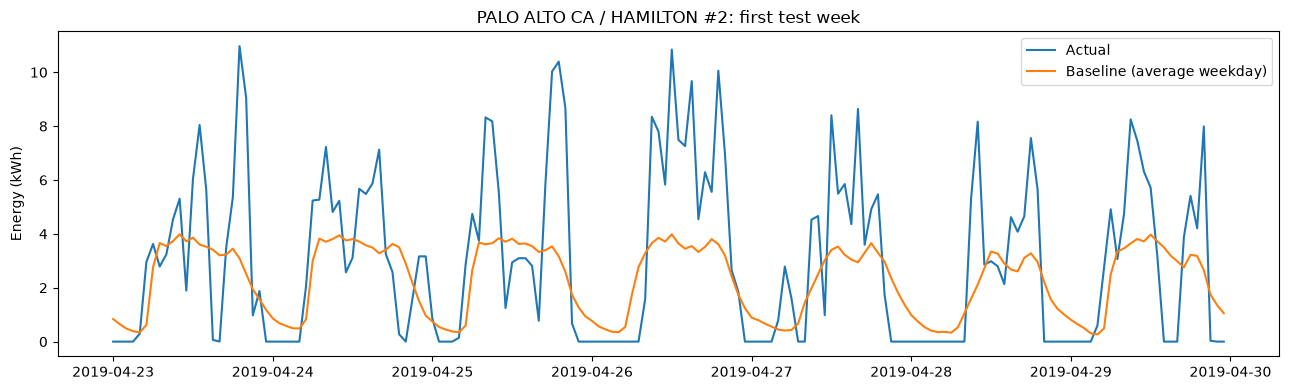

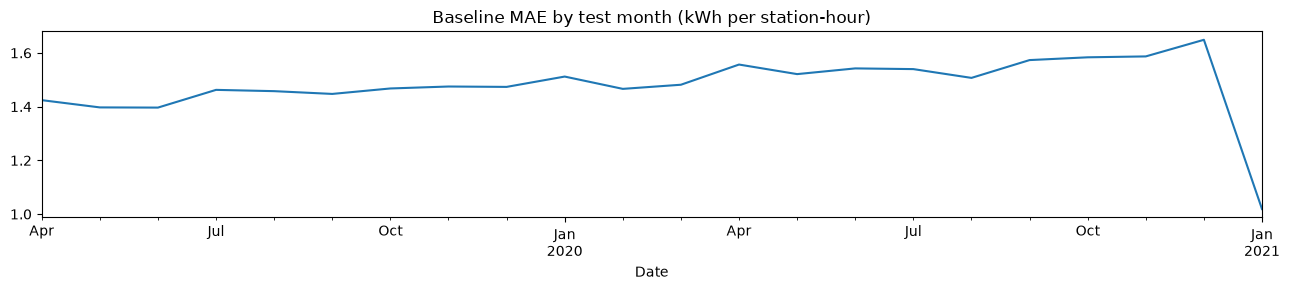

In [7]:
# First full test week at the station with the most test energy
station = scored.groupby("Station Name")["Energy (kWh)"].sum().idxmax()
week = scored[(scored["Station Name"] == station) & (scored["Date"] < scored["Date"].min() + pd.Timedelta(days=7))]
x = week["Hour"].dt.tz_convert(LOCAL_TZ)

plt.figure(figsize=(13, 4))
plt.plot(x, week["Energy (kWh)"], label="Actual")
plt.plot(x, week["Baseline"], label="Baseline (average weekday)")
plt.title(f"{station}: first test week")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

# Error by month shows where the baseline breaks down
monthly = scored.groupby(scored["Date"].dt.to_period("M"))[["Energy (kWh)", "Baseline"]].apply(
    lambda g: evaluate(g["Energy (kWh)"], g["Baseline"]))
monthly["MAE"].plot(figsize=(13, 3), title="Baseline MAE by test month (kWh per station-hour)")
plt.tight_layout()
plt.show()